# Captum tour: one verdict per layer

The two models are described in `01_data_and_models`; each tool in its own file.

In [1]:
from toy import *  # shared setup: data, the two models (trained once, then cached), helpers

## 25. One verdict per layer

```python
for layer in [fc1, fc2, fc3], from checkpoints at epochs 40, 50, 60:
    util, drift     ← LayerConductance (§13, §16)
    rank            ← width used, LayerActivation (§12)
    E_rel, E_trend  ← TracInCP push vs the median layer, and last / first checkpoint (§17)
loss_trend = probe loss, last / first checkpoint

if drift >= 0.02 or (loss_trend < 0.75 and E_trend >= 0.8):    → NOT CONVERGED
elif util >= 0.7 and rank >= 0.7 and E_rel >= 2 and E_trend >= 0.8:      → CAPACITY-BOUND
elif many idle units:                                           → UNDER-USED
else:                                       → converging normally (push shrinking) or settled
```

The thresholds are heuristics set on this toy problem. Use them to rank layers, and recalibrate on your own model.

In [2]:
@dataclass
class Thresholds:
    loss_improving: float = 0.75    # probe loss last / first below this = still improving
    drift: float = 0.02             # 1 - cos of unit importance between the last two checkpoints
    push_shrinking: float = 0.80    # E_trend below this = push shrinking
    saturated_util: float = 0.70
    saturated_rank: float = 0.70
    idle: float = 0.30
    push_rel: float = 2.0           # push per parameter vs the median layer


def verdict(r, th, loss_trend):
    improving = loss_trend < th.loss_improving
    shrinking = r["E_trend"] < th.push_shrinking
    saturated = r["util"] >= th.saturated_util and r["rank"] >= th.saturated_rank
    pulled = r["E_rel"] >= th.push_rel and not shrinking
    if r["drift"] >= th.drift or (improving and not shrinking):
        return "NOT CONVERGED" + (", saturated" if saturated else "")
    if saturated and pulled:
        return "CAPACITY-BOUND"
    if r["idle"] >= th.idle:
        return "UNDER-USED"
    if saturated:
        return "saturated, still improving" if shrinking else "saturated, settled"
    if pulled:
        return "large flat push"
    return "converging normally" if shrinking else "settled"


def diagnose(width, states, th=Thresholds()):
    """One row per layer from checkpoints `states` (oldest first, at least 2)."""
    first, prev, last = load(width, states[0]), load(width, states[-2]), load(width, states[-1])
    loss_trend = loss_acc(last, PX, PY)[0] / loss_acc(first, PX, PY)[0]
    push_first = {l: layer_push(width, states[0], l).mean().item() for l in LAYERS}
    push_last = {l: layer_push(width, states[-1], l).mean().item() for l in LAYERS}
    per_param = {l: push_last[l] / n_params(width, l) for l in LAYERS}
    median = float(np.median(list(per_param.values())))
    rows = []
    for l in LAYERS:
        imp_prev, imp = unit_importance(prev, l), unit_importance(last, l)
        r = dict(layer=l, util=entropy_count(imp) / len(imp), idle=float((imp < 0.05 * imp.mean()).float().mean()),
                 rank=width_used(last, l), drift=1 - F.cosine_similarity(imp, imp_prev, dim=0).item(),
                 E_rel=per_param[l] / median, E_trend=push_last[l] / push_first[l])
        r["verdict"] = verdict(r, th, loss_trend)
        rows.append(r)
    out = pd.DataFrame(rows).set_index("layer")
    out.attrs["loss_trend"] = loss_trend
    return out


SCENARIOS = {"wide, early (epochs 1, 2, 3)": ("wide", [1, 2, 3]),
             "wide, late (epochs 40, 50, 60)": ("wide", [40, 50, 60]),
             "narrow, late (epochs 40, 50, 60)": ("narrow", [40, 50, 60])}
reports = {}
for title, (name, epochs) in SCENARIOS.items():
    reports[title] = diagnose(WIDTH[name], [CKPTS[name][e] for e in epochs])
    print(f"\n{title}: probe loss last/first = {reports[title].attrs['loss_trend']:.2f}")
    display(reports[title].round(3))


wide, early (epochs 1, 2, 3): probe loss last/first = 0.34


,util,idle,rank,drift,E_rel,E_trend,verdict
layer,,,,,,,
fc1,0.932,0.000,0.142,0.004,5.090,4.994,NOT CONVERGED
fc2,0.947,0.000,0.107,0.002,0.753,2.819,NOT CONVERGED
fc3,0.809,0.156,0.081,0.002,1.000,2.515,NOT CONVERGED



wide, late (epochs 40, 50, 60): probe loss last/first = 0.46


,util,idle,rank,drift,E_rel,E_trend,verdict
layer,,,,,,,
fc1,0.952,0.000,0.134,0.0,14.470,0.500,converging normally
fc2,0.965,0.000,0.103,0.0,1.000,0.469,converging normally
fc3,0.835,0.141,0.083,0.0,0.975,0.471,converging normally



narrow, late (epochs 40, 50, 60): probe loss last/first = 0.93


,util,idle,rank,drift,E_rel,E_trend,verdict
layer,,,,,,,
fc1,0.841,0.000,0.099,0.002,1.000,1.667,settled
fc2,0.997,0.000,0.757,0.000,6.446,1.580,CAPACITY-BOUND
fc3,0.843,0.109,0.039,0.001,0.729,1.221,settled


The architecture view below collects one number per tool. It recomputes them here (§11, §14, §20, §21, §22, §24),
so this file runs on its own.

In [3]:
t0 = time.time()
drop = {"teacher (ceiling)": accuracy_drop(teacher), **{name: accuracy_drop(m) for name, m in MODELS.items()}}
unit_cost = {("LayerFeatureAblation", name, layer): unit_cost_of(m, layer)
             for name, m in MODELS.items() for layer in LAYERS}
knn = {name: same_label_knn(name, m) for name, m in MODELS.items()}
hidden_kept = hidden_gates_kept([0.01])
cav_acc = {}
for name, m in MODELS.items():
    cav_acc.update(run_tcav(name, m, [[concepts[j], r] for j in [5, 6, 7] for r in randoms])[0])
BN = {name: measure(m, SITES, FIT) for name, m in MODELS.items()}
print(f"recomputed in {time.time() - t0:.0f}s")

recomputed in 6s


**Everything on the architecture.** Late checkpoints, one line per tool. Input box: the share of the signals'
information captured (§11).

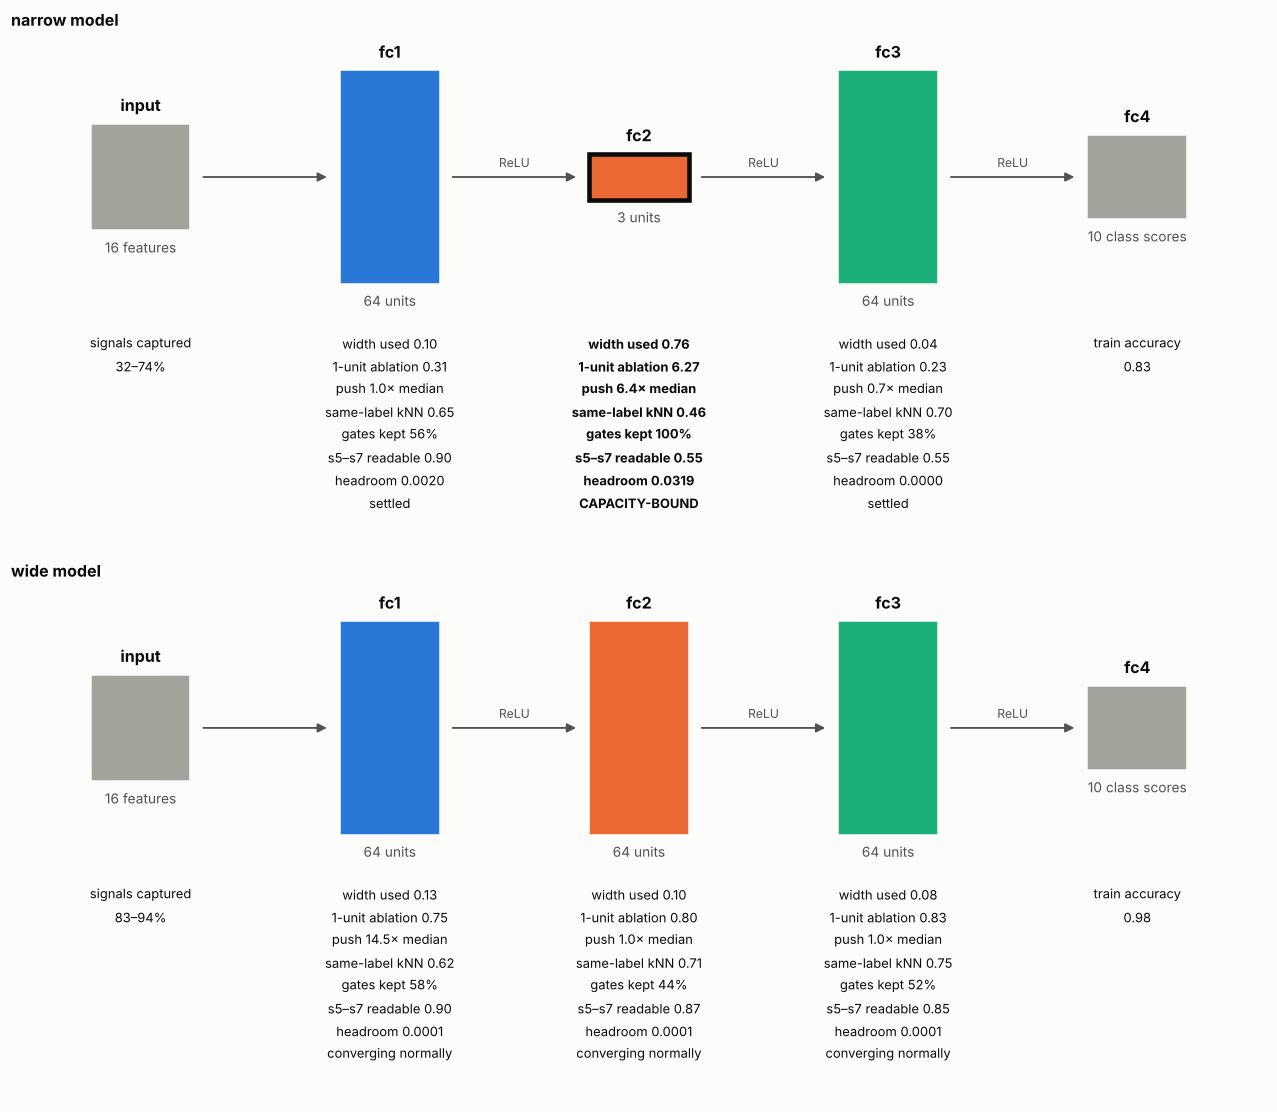

In [4]:
def notes_for(name):
    report = reports[f"{name}, late (epochs 40, 50, 60)"]
    captured = (drop[name][:8] / drop["teacher (ceiling)"][:8]) * 100
    notes = {"input": f"signals captured\n{captured.min():.0f}–{captured.max():.0f}%",
             "fc4": f"train accuracy\n{HIST[name].acc.iloc[-1]:.2f}"}
    for i, layer in enumerate(LAYERS):
        cost = unit_cost[("LayerFeatureAblation", name, layer)].mean().item()
        kept = hidden_kept[(hidden_kept.model == name) & (hidden_kept.layer == layer) & (hidden_kept.price == 0.01)].kept.item()
        weak = np.mean([cav_acc[(name, layer, f"{f} high", r.name)] for f in ["s5", "s6", "s7"] for r in randoms])
        notes[layer] = (f"width used {report.loc[layer, 'rank']:.2f}\n"
                        f"1-unit ablation {cost:.2f}\n"
                        f"push {report.loc[layer, 'E_rel']:.1f}× median\n"
                        f"same-label kNN {knn[name][i]:.2f}\n"
                        f"gates kept {kept:.0%}\n"
                        f"s5–s7 readable {weak:.2f}\n"
                        f"headroom {BN[name][layer].headroom:.4f}\n"
                        f"{report.loc[layer, 'verdict']}")
    return notes


fig, axes = plt.subplots(2, 1, figsize=(11.5, 10))
for ax, name in zip(axes, ["narrow", "wide"]):
    report = reports[f"{name}, late (epochs 40, 50, 60)"]
    flagged = [l for l in LAYERS if report.loc[l, "verdict"] == "CAPACITY-BOUND"]
    draw_architecture(ax, WIDTH[name], f"{name} model", notes=notes_for(name), flag=flagged[0] if flagged else None)
plt.show()

* **wide, early**: every layer is *not converged*. The loss is still falling fast and every layer's push grew.
  Drift is already small, so drift alone would have missed this run.
* **wide, late**: every layer is *converging normally*: the loss still falls and the push shrinks. `fc1`'s push is
  high but shrinking, so it is not flagged.
* **narrow, late**: the loss has stalled and only `fc2` is *capacity-bound*. Every tool agrees: full width, costly
  units, heavy push, mixed-up classes, no gate closes, weak signals lost, and the only real headroom (§24).

## 26. Does widening the flagged layer help?

```python
for width in [3, 6, 10, 16, 32, 64]:                # 3 and 64 are the two models above
    model = train(Student(width))
    verdict = diagnose(model, checkpoints at epochs 40, 50, 60)
    headroom = measure(model, sites, batches)["fc2"]          # §24
plot: final training loss, fc2 push, fc2 width used and fc2 headroom, against width
```

A capacity-bound verdict is a hypothesis: widening that layer should lower the **training** loss.

width sweep in 19s


,train_loss,loss_trend,fc2_headroom,fc2_unit_drop,fc2_rank,fc2_E_rel,fc2_E_trend,fc2_verdict,other_layers
width,,,,,,,,,
3,0.469,0.930,0.032,0.048,0.757,6.446,1.580,CAPACITY-BOUND,settled
6,0.118,0.810,0.001,0.001,0.887,2.089,1.155,CAPACITY-BOUND,settled
10,0.078,0.672,0.001,-0.012,0.583,1.518,1.008,NOT CONVERGED,NOT CONVERGED
16,0.064,0.584,0.001,-0.005,0.377,1.000,0.697,converging normally,converging normally
32,0.055,0.710,0.000,-0.002,0.196,1.000,0.846,NOT CONVERGED,"NOT CONVERGED, converging normally"
64,0.053,0.457,0.000,-0.000,0.103,1.000,0.469,converging normally,converging normally


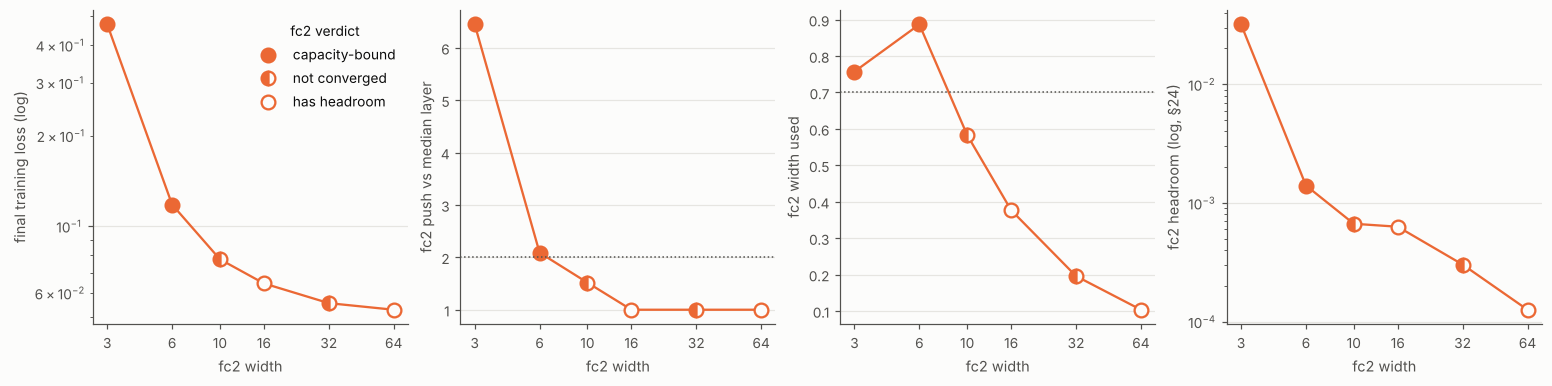

In [5]:
t0 = time.time()
sweep = []
for w in [3, 6, 10, 16, 32, 64]:
    if w in WIDTH.values():
        name = [k for k, v in WIDTH.items() if v == w][0]
        ckpts, hist = CKPTS[name], HIST[name]
    else:
        ckpts, hist = train(w)
    r = diagnose(w, [ckpts[e] for e in [40, 50, 60]])
    grown = load(w, ckpts[EPOCHS])
    b = measure(grown, SITES, FIT)["fc2"]
    sweep.append(dict(width=w, train_loss=hist.loss.iloc[-1], loss_trend=r.attrs["loss_trend"],
                      fc2_headroom=b.headroom, fc2_unit_drop=check(grown, SITES[1], b, FIT, CHECK)["drop"],
                      fc2_rank=r.loc["fc2", "rank"], fc2_E_rel=r.loc["fc2", "E_rel"],
                      fc2_E_trend=r.loc["fc2", "E_trend"], fc2_verdict=r.loc["fc2", "verdict"],
                      other_layers=", ".join(sorted(set(r.loc[["fc1", "fc3"], "verdict"])))))
sweep = pd.DataFrame(sweep).set_index("width")
print(f"width sweep in {time.time() - t0:.0f}s")
display(sweep.round(3))

MARKER = {"capacity-bound": dict(fillstyle="full", markerfacecolor=LAYER_COLOR["fc2"]),
          "not converged": dict(fillstyle="left", markerfacecolor=LAYER_COLOR["fc2"], markerfacecoloralt=SURFACE),
          "has headroom": dict(fillstyle="full", markerfacecolor=SURFACE)}
group = sweep.fc2_verdict.map(lambda v: "capacity-bound" if v.startswith("CAPACITY")
                              else "not converged" if v.startswith("NOT") else "has headroom")
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharex=True)
for ax, col, label, log in [(axes[0], "train_loss", "final training loss (log)", True),
                            (axes[1], "fc2_E_rel", "fc2 push vs median layer", False),
                            (axes[2], "fc2_rank", "fc2 width used", False),
                            (axes[3], "fc2_headroom", "fc2 headroom (log, §24)", True)]:
    ax.plot(sweep.index, sweep[col], color=LAYER_COLOR["fc2"], lw=1.5, zorder=1)
    for g, style in MARKER.items():
        sel = group == g
        if sel.any():
            ax.plot(sweep.index[sel], sweep[col][sel], ls="none", marker="o", ms=9, color=LAYER_COLOR["fc2"],
                    markeredgewidth=1.5, zorder=2, label=g, **style)
    ax.set_xscale("log", base=2)
    ax.set_xticks(sweep.index, [str(w) for w in sweep.index])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.grid(axis="x", visible=False)
    ax.set_xlabel("fc2 width")
    ax.set_ylabel(label)
    if log:
        ax.set_yscale("log")
axes[1].axhline(Thresholds().push_rel, color=INK2, lw=1, ls=":")
axes[2].axhline(Thresholds().saturated_rank, color=INK2, lw=1, ls=":")
axes[0].legend(title="fc2 verdict", title_fontsize=9)
plt.show()

* Widths 3 and 6 are flagged *capacity-bound*, and widening them does lower the training loss (0.47 → 0.12 → 0.08).
* From width 10 the flag turns off: `fc2` no longer saturates, and the remaining runs just need more training.
* `fc2` headroom (§24) falls steadily with width, 250× from 3 to 64, from one pass over the final model. Only at
  width 3 does its suggested unit pay off at once (loss −0.048). At width 6 it gains just 0.001, although retraining
  at width 10 lowers the loss by 0.04: a one-unit, first-order test underestimates what a retrain finds.

## 27. Using this on your own model

```python
states = checkpoints from late in training, oldest first      # e.g. epochs 40, 50, 60
probe  = 200–500 training examples, the same at every checkpoint

1. features:  DataLoaderAttribution(FeatureAblation(model)) at each checkpoint          # §11
              still rising = still learning
2. layers:    TracInCP push per layer (§17), LayerActivation width used (§12),
              LayerFeatureAblation per unit (§14)
3. confirm:   stochastic gates on the suspect layer (§21), TCAV readability (§22),
              expressivity bottleneck (§24): one pass, no checkpoints, gives the new unit's weights
              then widen that layer and retrain: training loss should drop (§26)
```

Keep in mind:

* Checkpoints should be 5–30% of the run apart.
* For `(N, T, D)` outputs (transformers), units are on dim 2. For other tasks, change the target and the loss.
* Run with `model.eval()` (dropout off, BatchNorm frozen).

**Captum features not shown**, and why:

| Feature | Why not here |
|---|---|
| `LayerGradCam`, `GuidedGradCam` | need convolutional feature maps |
| `LLMAttribution`, `LLMGradientAttribution`, `RemoteLLMAttribution`, `TextTemplateInput`, `TextTokenInput` | text generation |
| `ImageMaskInput` | image segments |
| `configure_interpretable_embedding_layer`, `TokenReferenceBase` | embedding layers |
| `ProductBaselines` | sampled baselines for structured (mostly text) inputs |
| `captum.attr.visualization` | plotting helpers for images, text and time series |